In [ ]:
# 06 — Spatial Hotspot Modeling (Experiment)
## Status: ARCHIVED (Not used for final energy simulation)

Objective:Predict the worst-case temperature (the hottest of the 48 sensors) instead of just one sensor.

Finding: 
While the model achieved a low MAE (0.276 °C), the baseline (predicting "no change") was actually better (0.164 °C) because hotspot temperatures
(likely exhaust air) are highly stable. Furthermore, attempting to cool a 35°C hotspot down to a 22°C setpoint resulted in unrealistic physics 
and only 1.4% energy savings.

decision: 
We rejected this approach for the final energy simulation. 
Instead, we will proceed with predicting the **Average Room Temperature**, which better represents the cold aisle environment
 and provides a more realistic cooling target.

In [2]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. Load Data
aau = pd.read_csv(r"D:\Projects\datacenter-efficiencyDMP\data\raw\AAU_temperature_and_power_use.csv")
aau['Time [Date/Time]'] = pd.to_datetime(aau['Time [Date/Time]'])

# 2. Identify ALL temperature columns
temp_cols = [c for c in aau.columns if c.startswith('Temperature')]
print(f"Found {len(temp_cols)} temperature sensors.")

# 3. Create the "Hotspot" (Max temp across all sensors at each second)
aau['Room_Max_Temp'] = aau[temp_cols].max(axis=1)

# Keep only time, the hotspot, and power
cols_to_keep = ['Time [Date/Time]', 'Room_Max_Temp', 'Power Ch 1 (W)', 'Power Ch 2 (W)', 'Power Ch 3 (W)']
df = aau[cols_to_keep].copy()

# 4. Downsample to 1 minute
df = df.set_index('Time [Date/Time]').resample('1min').mean().reset_index()
df = df.rename(columns={
    'Time [Date/Time]': 'time', 
    'Room_Max_Temp': 'temp',
    'Power Ch 1 (W)': 'power_1', 'Power Ch 2 (W)': 'power_2', 'Power Ch 3 (W)': 'power_3'
})

print("Max room temp range:", df['temp'].min(), "to", df['temp'].max(), "°C")

Found 48 temperature sensors.
Max room temp range: 28.336564133333333 to 38.84302878333333 °C


In [3]:
# Time features
df['hour'] = df['time'].dt.hour
df['minute'] = df['time'].dt.minute
df['regime'] = (df['time'] >= '2024-09-28').astype(int)

# Target: 60 min ahead
df['temp_target_60m'] = df['temp'].shift(-60)

# Lags
df['temp_lag_1m']  = df['temp'].shift(1)
df['temp_lag_5m']  = df['temp'].shift(5)
df['temp_lag_15m'] = df['temp'].shift(15)
df['temp_lag_60m'] = df['temp'].shift(60)
df['power_1_lag_1m'] = df['power_1'].shift(1)
df['power_1_lag_5m'] = df['power_1'].shift(5)
df['temp_rolling_mean_15m'] = df['temp'].rolling(window=15).mean()

df_clean = df.dropna().reset_index(drop=True)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002116 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2634
[LightGBM] [Info] Number of data points in the train set: 16202, number of used features: 12
[LightGBM] [Info] Start training from score 32.788572
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

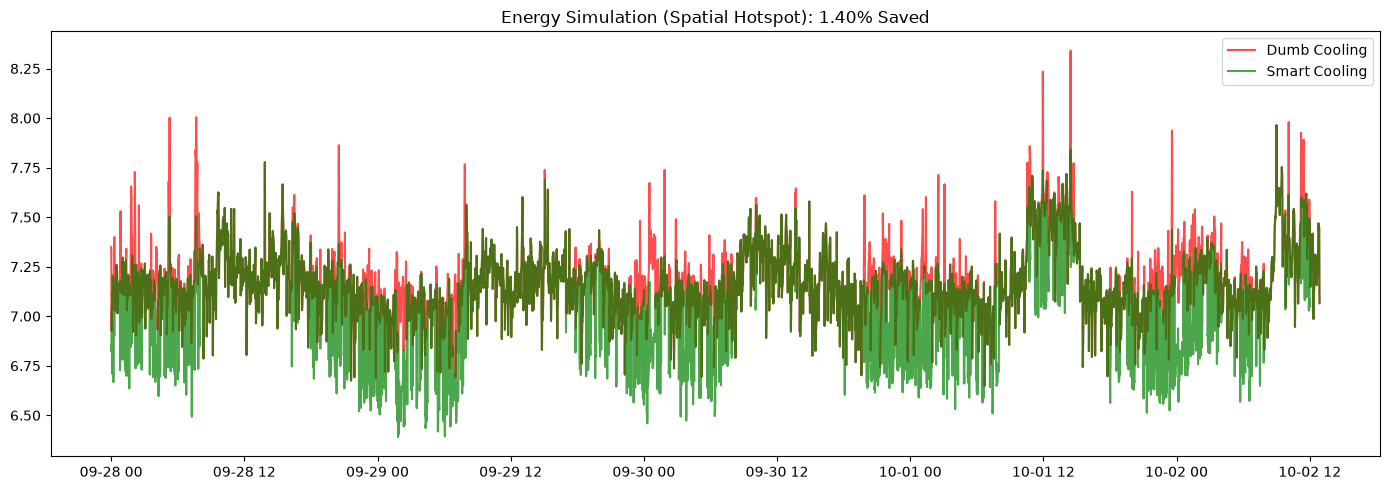

In [5]:
# Split
split_date = pd.to_datetime('2024-09-28')
train = df_clean[df_clean['time'] < split_date]
test  = df_clean[df_clean['time'] >= split_date]

features = ['power_1', 'power_2', 'power_3', 'hour', 'minute', 'regime', 
            'temp_lag_1m', 'temp_lag_5m', 'temp_lag_15m', 'temp_lag_60m', 
            'power_1_lag_1m', 'power_1_lag_5m', 'temp_rolling_mean_15m']

X_train, y_train = train[features], train['temp_target_60m']
X_test, y_test = test[features], test['temp_target_60m']

# Train
model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=7, random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, predictions)
baseline_mae = mean_absolute_error(y_test, test['temp'])
print(f"Hotspot 60-Min MAE: {mae:.3f} °C")
print(f"Hotspot Baseline MAE: {baseline_mae:.3f} °C")

# --- ENERGY SIMULATION ---
results = pd.DataFrame({
    'time': test['time'].values,
    'actual_temp': y_test.values,
    'predicted_temp': predictions
})

# Baseline: Keep room at 22.0°C
baseline_energy = (results['actual_temp'] - 22.0).clip(lower=1.0)

# Smart: Relax target if we predict a drop
smart_energy = []
for i in range(len(results)):
    if results['predicted_temp'].iloc[i] < results['actual_temp'].iloc[i]:
        current_target = 22.5 
    else:
        current_target = 22.0
    energy = max(1.0, results['actual_temp'].iloc[i] - current_target)
    smart_energy.append(energy)

results['baseline_energy'] = baseline_energy
results['smart_energy'] = smart_energy

savings = ((results['baseline_energy'].sum() - sum(smart_energy)) / results['baseline_energy'].sum()) * 100
print(f"NEW Energy Saved: {savings:.2f}%")

# Plot
plt.figure(figsize=(14, 5))
plt.plot(results['time'], results['baseline_energy'], label='Dumb Cooling', color='red', alpha=0.7)
plt.plot(results['time'], smart_energy, label='Smart Cooling', color='green', alpha=0.7)
plt.title(f'Energy Simulation (Spatial Hotspot): {savings:.2f}% Saved')
plt.legend()
plt.tight_layout()
plt.savefig('D:/Projects/datacenter-efficiencyDMP/reports/figures/06_spatial_energy.png', dpi=150)
plt.show()